In [1]:
# ============================================================
# Outcome II — Physical planet properties
# Notebook limpio desde cero
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

# Cargar catálogo raw original
df = pd.read_csv(
    "../data_raw/nasa_exoplanets_raw_2026_07_21.csv",
    comment="#"
)

df.shape

(6324, 127)

In [2]:
# ============================================================
# Revisar columnas necesarias
# ============================================================

columnas_necesarias = [
    "pl_name",
    "hostname",
    "pl_rade",
    "pl_bmasse",
    "pl_radelim",
    "pl_bmasselim",
    "pl_bmassprov",
    "st_mass",
    "st_met",
    "st_rad",
    "st_teff",
    "pl_orbper",
    "pl_orbsmax",
    "pl_insol"
]

columnas_presentes = [c for c in columnas_necesarias if c in df.columns]
columnas_faltantes = [c for c in columnas_necesarias if c not in df.columns]

print("Columnas presentes:")
print(columnas_presentes)

print("\nColumnas faltantes:")
print(columnas_faltantes)

Columnas presentes:
['pl_name', 'hostname', 'pl_rade', 'pl_bmasse', 'pl_radelim', 'pl_bmasselim', 'pl_bmassprov', 'st_mass', 'st_met', 'st_rad', 'st_teff', 'pl_orbper', 'pl_orbsmax', 'pl_insol']

Columnas faltantes:
[]


In [3]:
# ============================================================
# Calcular irradiación incidente
# ============================================================

T_sun = 5772  # K

# Periodo orbital en años
df["P_years"] = df["pl_orbper"] / 365.25

# Semieje mayor derivado con Kepler:
# a/AU = [Mstar * (P/yr)^2]^(1/3)
df["a_kepler_au"] = (
    df["st_mass"] * df["P_years"]**2
) ** (1/3)

# Usar semieje catalogado si existe; si no, usar Kepler
df["a_final_au"] = df["pl_orbsmax"].copy()

df.loc[
    df["a_final_au"].isna(),
    "a_final_au"
] = df.loc[
    df["a_final_au"].isna(),
    "a_kepler_au"
]

df["a_origen"] = np.where(
    df["pl_orbsmax"].notna(),
    "catalogado",
    "kepler_derivado"
)

# Irradiación calculada en unidades terrestres
df["insol_calculada"] = (
    (df["st_rad"] ** 2) *
    (df["st_teff"] / T_sun) ** 4 *
    (1 / df["a_final_au"] ** 2)
)

df["log_insol_calculada"] = np.log10(df["insol_calculada"])

df[
    [
        "pl_name",
        "pl_rade",
        "pl_bmasse",
        "pl_orbper",
        "pl_orbsmax",
        "a_kepler_au",
        "a_final_au",
        "a_origen",
        "pl_insol",
        "insol_calculada",
        "log_insol_calculada"
    ]
].head()

,pl_name,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,a_kepler_au,a_final_au,a_origen,pl_insol,insol_calculada,log_insol_calculada
0,11 Com b,12.2,4914.898486,323.21000,1.178,1.178452,1.178,catalogado,68.5387,69.371821,1.841183
1,11 UMi b,12.3,4684.814200,516.21997,1.530,1.770835,1.530,catalogado,114.8502,107.601591,2.031819
2,14 And b,13.1,1131.151301,186.76000,0.775,0.774942,0.775,catalogado,115.1634,114.229970,2.057780
3,14 Her b,12.5,2828.672822,1766.41000,2.839,2.830902,2.839,catalogado,0.0873,0.078495,-1.105156
4,16 Cyg B b,13.5,565.737400,798.50000,1.660,1.728215,1.660,catalogado,0.4540,0.456359,-0.340693


In [4]:
# ============================================================
# P0 — Outcome II: muestra científica mass-radius
# ============================================================

filas = []

def agregar_fila(nombre, data):
    filas.append({
        "sample": nombre,
        "N_planets": len(data),
        "N_hosts": data["hostname"].nunique()
    })

# 1. Masa + radio disponibles
s1 = df[
    df["pl_rade"].notna() &
    df["pl_bmasse"].notna() &
    df["hostname"].notna()
].copy()

agregar_fila("Mass + radius available", s1)

# 2. Eliminar límites
s2 = s1[
    (s1["pl_radelim"].fillna(0) == 0) &
    (s1["pl_bmasselim"].fillna(0) == 0)
].copy()

agregar_fila("No upper/lower limits", s2)

# 3. Solo masas verdaderas
s3 = s2[
    s2["pl_bmassprov"] == "Mass"
].copy()

agregar_fila("True Mass only", s3)

# 4. + masa estelar
s4 = s3[
    s3["st_mass"].notna()
].copy()

agregar_fila("+ Mstar", s4)

# 5. + metalicidad
s5 = s4[
    s4["st_met"].notna()
].copy()

agregar_fila("+ [Fe/H]", s5)

# 6. + irradiación calculada
s6 = s5[
    s5["log_insol_calculada"].notna()
].copy()

agregar_fila("+ F", s6)

# 7. Planetas pequeños
s7 = s6[
    (s6["pl_rade"] > 1.0) &
    (s6["pl_rade"] < 4.0)
].copy()

agregar_fila("Small (1 < Rp < 4 Rearth)", s7)

tabla_P0_outcomeII = pd.DataFrame(filas)

sample_physical_properties = s7.copy()

tabla_P0_outcomeII.to_csv(
    "../tables/P0_outcomeII_mass_radius_sample_cuts.csv",
    index=False
)

sample_physical_properties.to_csv(
    "../data_processed/sample_outcomeII_physical_properties.csv",
    index=False
)

tabla_P0_outcomeII

,sample,N_planets,N_hosts
0,Mass + radius available,6250,4701
1,No upper/lower limits,6061,4622
2,True Mass only,2182,1804
3,+ Mstar,2176,1798
4,+ [Fe/H],1800,1438
5,+ F,1798,1436
6,Small (1 < Rp < 4 Rearth),593,391


In [5]:
# ============================================================
# Confirmar muestra final
# ============================================================

print("sample_physical_properties shape:")
print(sample_physical_properties.shape)

print("\nN planetas:")
print(len(sample_physical_properties))

print("\nN hosts:")
print(sample_physical_properties["hostname"].nunique())

sample_physical_properties[
    [
        "pl_name",
        "hostname",
        "pl_rade",
        "pl_bmasse",
        "pl_bmassprov",
        "st_mass",
        "st_met",
        "insol_calculada"
    ]
].head()

sample_physical_properties shape:
(593, 133)

N planetas:
593

N hosts:
391


,pl_name,hostname,pl_rade,pl_bmasse,pl_bmassprov,st_mass,st_met,insol_calculada
36,55 Cnc e,55 Cnc,1.87500,7.990000,Mass,0.905,0.35,2404.681535
55,AU Mic c,AU Mic,2.79000,14.460000,Mass,0.635,0.01,7.423836
56,AU Mic d,AU Mic,1.02000,1.053000,Mass,0.510,0.23,12.550241
66,BD+20 594 b,BD+20 594,2.57807,22.248100,Mass,1.670,-0.15,19.998927
135,CoRoT-7 b,CoRoT-7,1.68135,4.076605,Mass,0.820,0.05,1659.685490


In [6]:
# ============================================================
# Clasificación observacional por radio
# ============================================================

def clasificar_radio(r):
    if pd.isna(r):
        return "sin_dato"
    elif r < 1.25:
        return "Earth-size"
    elif r < 2.0:
        return "Super-Earth"
    elif r < 6.0:
        return "Neptune-size"
    elif r < 15.0:
        return "Jupiter-size"
    else:
        return "larger_than_Jupiter"

sample_physical_properties["radius_class"] = (
    sample_physical_properties["pl_rade"].apply(clasificar_radio)
)

tabla_radius_class_outcomeII = (
    sample_physical_properties["radius_class"]
    .value_counts()
    .reset_index()
)

tabla_radius_class_outcomeII.columns = [
    "radius_class",
    "N_planets"
]

tabla_radius_class_outcomeII

,radius_class,N_planets
0,Neptune-size,386
1,Super-Earth,162
2,Earth-size,45


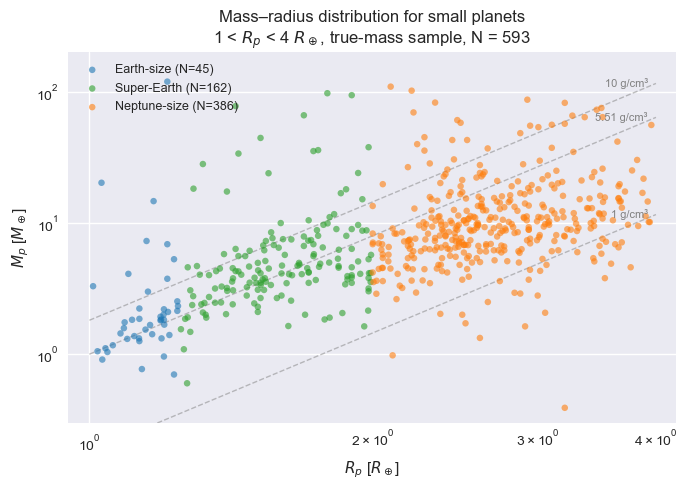

In [7]:
# ============================================================
# P1 — Figura mass-radius
# ============================================================

df_mr = sample_physical_properties.copy()

orden_clases = [
    "Earth-size",
    "Super-Earth",
    "Neptune-size"
]

colores = {
    "Earth-size": "tab:blue",
    "Super-Earth": "tab:green",
    "Neptune-size": "tab:orange"
}

plt.figure(figsize=(7, 5))

# Líneas de densidad constante
R_grid = np.logspace(np.log10(1.0), np.log10(4.0), 200)

rho_earth = 5.51  # g/cm3
densidades = [1, 5.51, 10]

for rho in densidades:
    M_line = (rho / rho_earth) * R_grid**3
    
    plt.plot(
        R_grid,
        M_line,
        linestyle="--",
        linewidth=1,
        alpha=0.5,
        color="gray",
        zorder=1
    )
    
    plt.text(
        R_grid[-1] * 0.98,
        M_line[-1],
        f"{rho:g} g/cm³",
        fontsize=8,
        va="center",
        ha="right",
        color="gray"
    )

# Puntos
for clase in orden_clases:
    subset = df_mr[df_mr["radius_class"] == clase]
    
    plt.scatter(
        subset["pl_rade"],
        subset["pl_bmasse"],
        s=22,
        alpha=0.60,
        label=f"{clase} (N={len(subset)})",
        color=colores[clase],
        edgecolor="none",
        zorder=2
    )

plt.xscale("log")
plt.yscale("log")

plt.xlim(0.95, 4.2)
plt.ylim(0.3, 200)

plt.xlabel(r"$R_p$ [$R_\oplus$]")
plt.ylabel(r"$M_p$ [$M_\oplus$]")

plt.title(
    f"Mass–radius distribution for small planets\n"
    f"1 < $R_p$ < 4 $R_\\oplus$, true-mass sample, N = {len(df_mr)}"
)

plt.legend(fontsize=9, loc="upper left")
plt.tight_layout()

plt.savefig(
    "../figures/P1_outcomeII_mass_radius_small_planets.png",
    dpi=300
)

plt.show()

In [8]:
# ============================================================
# P2 — Outcome II: baseline mass-radius model
# M0: log Mp ~ spline(log Rp)
# 5-fold CV agrupada por hostname
# ============================================================

import statsmodels.api as sm
from patsy import dmatrix
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ----------------------------
# 1. Preparar muestra
# ----------------------------

df_mr_model = sample_physical_properties[
    sample_physical_properties["pl_rade"].notna() &
    sample_physical_properties["pl_bmasse"].notna() &
    sample_physical_properties["hostname"].notna() &
    (sample_physical_properties["pl_rade"] > 0) &
    (sample_physical_properties["pl_bmasse"] > 0)
].copy()

df_mr_model["log_Rp"] = np.log10(df_mr_model["pl_rade"])
df_mr_model["log_Mp"] = np.log10(df_mr_model["pl_bmasse"])

print("N planetas:", len(df_mr_model))
print("N hosts:", df_mr_model["hostname"].nunique())

N planetas: 593
N hosts: 391


In [9]:
# ----------------------------
# 2. Modelo spline baseline
# ----------------------------

spline_formula = "bs(log_Rp, df=4, degree=3, include_intercept=False)"

X_spline = dmatrix(
    spline_formula,
    data=df_mr_model,
    return_type="dataframe"
)

y = df_mr_model["log_Mp"]

modelo_mr_M0 = sm.OLS(y, X_spline).fit()

print(modelo_mr_M0.summary())

                            OLS Regression Results                            
Dep. Variable:                 log_Mp   R-squared:                       0.287
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     59.06
Date:                Fri, 21 Aug 2026   Prob (F-statistic):           6.40e-42
Time:                        10:40:42   Log-Likelihood:                -247.98
No. Observations:                 593   AIC:                             506.0
Df Residuals:                     588   BIC:                             527.9
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                                             coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------

In [10]:
# ----------------------------
# 3. Métricas in-sample
# ----------------------------

pred_insample = modelo_mr_M0.predict(X_spline)

rmse_insample = mean_squared_error(
    y,
    pred_insample,
    squared=False
)

mae_insample = mean_absolute_error(
    y,
    pred_insample
)

r2_insample = r2_score(
    y,
    pred_insample
)

tabla_mr_M0_insample = pd.DataFrame({
    "modelo": ["MR_M0_spline_logRp"],
    "formula": ["logMp ~ spline(logRp, df=4)"],
    "N": [len(df_mr_model)],
    "N_hosts": [df_mr_model["hostname"].nunique()],
    "R2_insample": [r2_insample],
    "RMSE_insample": [rmse_insample],
    "MAE_insample": [mae_insample],
    "AIC": [modelo_mr_M0.aic],
    "BIC": [modelo_mr_M0.bic]
}).round(4)

tabla_mr_M0_insample.to_csv(
    "../tables/P2_outcomeII_M0_mass_radius_spline_insample.csv",
    index=False
)

tabla_mr_M0_insample

,modelo,formula,N,N_hosts,R2_insample,RMSE_insample,MAE_insample,AIC,BIC
0,MR_M0_spline_logRp,"logMp ~ spline(logRp, df=4)",593,391,0.2866,0.3676,0.2437,505.9674,527.8933


In [11]:
# ----------------------------
# 4. Residuales
# ----------------------------

df_mr_model["log_Mp_pred_M0"] = pred_insample
df_mr_model["resid_log_Mp_M0"] = (
    df_mr_model["log_Mp"] - df_mr_model["log_Mp_pred_M0"]
)

tabla_resid_M0 = df_mr_model["resid_log_Mp_M0"].describe().to_frame().T.round(4)

tabla_resid_M0.to_csv(
    "../tables/P2_outcomeII_M0_residual_distribution.csv",
    index=False
)

tabla_resid_M0

,count,mean,std,min,25%,50%,75%,max
resid_log_Mp_M0,593.0,0.0,0.3679,-1.515,-0.1811,-0.0549,0.1205,2.8174


In [12]:
# ----------------------------
# 5. 5-fold CV agrupada por hostname
# ----------------------------

gkf = GroupKFold(n_splits=5)

cv_rows = []

groups = df_mr_model["hostname"]

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(df_mr_model, y, groups=groups),
    start=1
):
    train = df_mr_model.iloc[train_idx].copy()
    test = df_mr_model.iloc[test_idx].copy()
    
    # Verificar que no se compartan hosts
    overlap_hosts = set(train["hostname"]).intersection(set(test["hostname"]))
    assert len(overlap_hosts) == 0
    
    X_train = dmatrix(
        spline_formula,
        data=train,
        return_type="dataframe"
    )
    
    X_test = dmatrix(
        spline_formula,
        data=test,
        return_type="dataframe"
    )
    
    y_train = train["log_Mp"]
    y_test = test["log_Mp"]
    
    model_cv = sm.OLS(y_train, X_train).fit()
    pred_test = model_cv.predict(X_test)
    
    cv_rows.append({
        "fold": fold,
        "N_train": len(train),
        "N_test": len(test),
        "N_hosts_train": train["hostname"].nunique(),
        "N_hosts_test": test["hostname"].nunique(),
        "R2_test": r2_score(y_test, pred_test),
        "RMSE_test": mean_squared_error(y_test, pred_test, squared=False),
        "MAE_test": mean_absolute_error(y_test, pred_test)
    })

tabla_cv_mr_M0_folds = pd.DataFrame(cv_rows).round(4)

tabla_cv_mr_M0_resumen = pd.DataFrame({
    "modelo": ["MR_M0_spline_logRp"],
    "CV_R2_mean": [tabla_cv_mr_M0_folds["R2_test"].mean()],
    "CV_R2_std": [tabla_cv_mr_M0_folds["R2_test"].std()],
    "CV_RMSE_mean": [tabla_cv_mr_M0_folds["RMSE_test"].mean()],
    "CV_RMSE_std": [tabla_cv_mr_M0_folds["RMSE_test"].std()],
    "CV_MAE_mean": [tabla_cv_mr_M0_folds["MAE_test"].mean()],
    "CV_MAE_std": [tabla_cv_mr_M0_folds["MAE_test"].std()]
}).round(4)

tabla_cv_mr_M0_folds.to_csv(
    "../tables/P2_outcomeII_M0_CV_folds_grouped_by_hostname.csv",
    index=False
)

tabla_cv_mr_M0_resumen.to_csv(
    "../tables/P2_outcomeII_M0_CV_summary_grouped_by_hostname.csv",
    index=False
)

tabla_cv_mr_M0_resumen

,modelo,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std
0,MR_M0_spline_logRp,0.255,0.0968,0.3724,0.0231,0.2466,0.0213


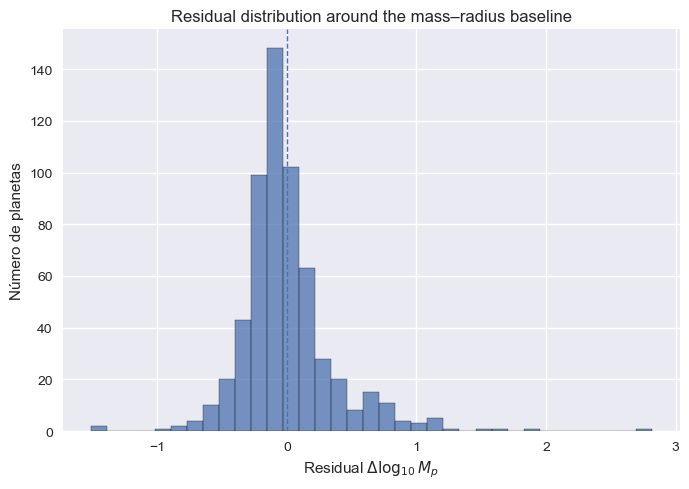

In [13]:
# ----------------------------
# 6. Figura de residuales
# ----------------------------

plt.figure(figsize=(7, 5))

plt.hist(
    df_mr_model["resid_log_Mp_M0"],
    bins=35,
    alpha=0.75,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel(r"Residual $\Delta \log_{10} M_p$")
plt.ylabel("Número de planetas")
plt.title("Residual distribution around the mass–radius baseline")

plt.tight_layout()

plt.savefig(
    "../figures/P2_outcomeII_M0_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# ============================================================
# P3 — Outcome II: ¿añade información la irradiación?
# M1: logMp ~ spline(logRp) + logF
# Comparación M0 -> M1
# ============================================================

from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from patsy import dmatrix
import statsmodels.api as sm

# ----------------------------
# 1. Preparar muestra común
# ----------------------------

df_mr_p3 = df_mr_model[
    df_mr_model["log_Rp"].notna() &
    df_mr_model["log_Mp"].notna() &
    df_mr_model["log_insol_calculada"].notna() &
    df_mr_model["hostname"].notna()
].copy()

df_mr_p3["logF"] = df_mr_p3["log_insol_calculada"]

print("N planetas:", len(df_mr_p3))
print("N hosts:", df_mr_p3["hostname"].nunique())

N planetas: 593
N hosts: 391


In [15]:
# ----------------------------
# 2. M0 y M1 in-sample
# ----------------------------

spline_formula = "bs(log_Rp, df=4, degree=3, include_intercept=False)"

X_spline = dmatrix(
    spline_formula,
    data=df_mr_p3,
    return_type="dataframe"
)

# M0: solo relación mass-radius
X_M0 = X_spline.copy()

# M1: mass-radius + irradiación
X_M1 = X_spline.copy()
X_M1["logF"] = df_mr_p3["logF"].values

y = df_mr_p3["log_Mp"]

modelo_mr_M0_p3 = sm.OLS(y, X_M0).fit()
modelo_mr_M1 = sm.OLS(y, X_M1).fit()

pred_M0 = modelo_mr_M0_p3.predict(X_M0)
pred_M1 = modelo_mr_M1.predict(X_M1)

tabla_p3_insample = pd.DataFrame({
    "Model": ["M0", "M1"],
    "Predictors": [
        "spline(logRp)",
        "spline(logRp) + logF"
    ],
    "N": [
        int(modelo_mr_M0_p3.nobs),
        int(modelo_mr_M1.nobs)
    ],
    "N_hosts": [
        df_mr_p3["hostname"].nunique(),
        df_mr_p3["hostname"].nunique()
    ],
    "AIC": [
        modelo_mr_M0_p3.aic,
        modelo_mr_M1.aic
    ],
    "BIC": [
        modelo_mr_M0_p3.bic,
        modelo_mr_M1.bic
    ],
    "R2_insample": [
        r2_score(y, pred_M0),
        r2_score(y, pred_M1)
    ],
    "RMSE_insample": [
        mean_squared_error(y, pred_M0, squared=False),
        mean_squared_error(y, pred_M1, squared=False)
    ],
    "MAE_insample": [
        mean_absolute_error(y, pred_M0),
        mean_absolute_error(y, pred_M1)
    ]
})

tabla_p3_insample["delta_AIC_vs_M0"] = (
    tabla_p3_insample["AIC"] - tabla_p3_insample.loc[0, "AIC"]
)

tabla_p3_insample["delta_R2_vs_M0"] = (
    tabla_p3_insample["R2_insample"] - tabla_p3_insample.loc[0, "R2_insample"]
)

tabla_p3_insample["delta_RMSE_vs_M0"] = (
    tabla_p3_insample["RMSE_insample"] - tabla_p3_insample.loc[0, "RMSE_insample"]
)

tabla_p3_insample = tabla_p3_insample.round(4)

tabla_p3_insample.to_csv(
    "../tables/P3_outcomeII_M0_vs_M1_insample_logF.csv",
    index=False
)

tabla_p3_insample

,Model,Predictors,N,N_hosts,AIC,BIC,R2_insample,RMSE_insample,MAE_insample,delta_AIC_vs_M0,delta_R2_vs_M0,delta_RMSE_vs_M0
0,M0,spline(logRp),593,391,505.9674,527.8933,0.2866,0.3676,0.2437,0.0000,0.0000,0.0000
1,M1,spline(logRp) + logF,593,391,498.8092,525.1204,0.2976,0.3648,0.2396,-7.1581,0.0109,-0.0028


In [16]:
# ----------------------------
# 3. Coeficiente de logF en M1
# ----------------------------

tabla_coef_logF_M1 = pd.DataFrame({
    "model": ["M1"],
    "predictor": ["logF"],
    "coef": [modelo_mr_M1.params["logF"]],
    "IC95_low": [modelo_mr_M1.conf_int().loc["logF", 0]],
    "IC95_high": [modelo_mr_M1.conf_int().loc["logF", 1]],
    "p_value": [modelo_mr_M1.pvalues["logF"]]
}).round(4)

tabla_coef_logF_M1.to_csv(
    "../tables/P3_outcomeII_M1_logF_coefficient.csv",
    index=False
)

tabla_coef_logF_M1

,model,predictor,coef,IC95_low,IC95_high,p_value
0,M1,logF,0.061,0.0214,0.1007,0.0026


In [17]:
# ----------------------------
# 4. 5-fold CV agrupada por hostname
# ----------------------------

gkf = GroupKFold(n_splits=5)

cv_rows_p3 = []

groups = df_mr_p3["hostname"]

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(df_mr_p3, y, groups=groups),
    start=1
):
    train = df_mr_p3.iloc[train_idx].copy()
    test = df_mr_p3.iloc[test_idx].copy()
    
    overlap_hosts = set(train["hostname"]).intersection(set(test["hostname"]))
    assert len(overlap_hosts) == 0
    
    y_train = train["log_Mp"]
    y_test = test["log_Mp"]
    
    X_train_spline = dmatrix(
        spline_formula,
        data=train,
        return_type="dataframe"
    )
    
    X_test_spline = dmatrix(
        spline_formula,
        data=test,
        return_type="dataframe"
    )
    
    # M0
    X_train_M0 = X_train_spline.copy()
    X_test_M0 = X_test_spline.copy()
    
    model_M0_cv = sm.OLS(y_train, X_train_M0).fit()
    pred_M0_test = model_M0_cv.predict(X_test_M0)
    
    cv_rows_p3.append({
        "fold": fold,
        "Model": "M0",
        "N_train": len(train),
        "N_test": len(test),
        "N_hosts_train": train["hostname"].nunique(),
        "N_hosts_test": test["hostname"].nunique(),
        "R2_test": r2_score(y_test, pred_M0_test),
        "RMSE_test": mean_squared_error(y_test, pred_M0_test, squared=False),
        "MAE_test": mean_absolute_error(y_test, pred_M0_test)
    })
    
    # M1
    X_train_M1 = X_train_spline.copy()
    X_test_M1 = X_test_spline.copy()
    
    X_train_M1["logF"] = train["logF"].values
    X_test_M1["logF"] = test["logF"].values
    
    model_M1_cv = sm.OLS(y_train, X_train_M1).fit()
    pred_M1_test = model_M1_cv.predict(X_test_M1)
    
    cv_rows_p3.append({
        "fold": fold,
        "Model": "M1",
        "N_train": len(train),
        "N_test": len(test),
        "N_hosts_train": train["hostname"].nunique(),
        "N_hosts_test": test["hostname"].nunique(),
        "R2_test": r2_score(y_test, pred_M1_test),
        "RMSE_test": mean_squared_error(y_test, pred_M1_test, squared=False),
        "MAE_test": mean_absolute_error(y_test, pred_M1_test)
    })

tabla_cv_p3_folds = pd.DataFrame(cv_rows_p3).round(4)

tabla_cv_p3_summary = (
    tabla_cv_p3_folds
    .groupby("Model")
    .agg(
        CV_R2_mean=("R2_test", "mean"),
        CV_R2_std=("R2_test", "std"),
        CV_RMSE_mean=("RMSE_test", "mean"),
        CV_RMSE_std=("RMSE_test", "std"),
        CV_MAE_mean=("MAE_test", "mean"),
        CV_MAE_std=("MAE_test", "std")
    )
    .reset_index()
)

m0_rmse = tabla_cv_p3_summary.loc[
    tabla_cv_p3_summary["Model"] == "M0",
    "CV_RMSE_mean"
].iloc[0]

m0_r2 = tabla_cv_p3_summary.loc[
    tabla_cv_p3_summary["Model"] == "M0",
    "CV_R2_mean"
].iloc[0]

tabla_cv_p3_summary["delta_CV_RMSE_vs_M0"] = (
    tabla_cv_p3_summary["CV_RMSE_mean"] - m0_rmse
)

tabla_cv_p3_summary["delta_CV_R2_vs_M0"] = (
    tabla_cv_p3_summary["CV_R2_mean"] - m0_r2
)

tabla_cv_p3_summary = tabla_cv_p3_summary.round(4)

tabla_cv_p3_folds.to_csv(
    "../tables/P3_outcomeII_M0_vs_M1_CV_folds_grouped_by_hostname.csv",
    index=False
)

tabla_cv_p3_summary.to_csv(
    "../tables/P3_outcomeII_M0_vs_M1_CV_summary_grouped_by_hostname.csv",
    index=False
)

tabla_cv_p3_summary

,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std,delta_CV_RMSE_vs_M0,delta_CV_R2_vs_M0
0,M0,0.2550,0.0968,0.3724,0.0231,0.2466,0.0213,0.0000,0.0000
1,M1,0.2585,0.0892,0.3719,0.0275,0.2452,0.0172,-0.0005,0.0035


Al añadir irradiación al modelo flexible masa–radio, el ajuste in-sample mejora ligeramente: el AIC disminuye de 505.97 a 498.81 y el R² aumenta de 0.287 a 0.298. El coeficiente de logF es positivo y significativo. Sin embargo, la mejora en validación cruzada agrupada por estrella es prácticamente nula, con un RMSE que cambia de 0.3724 a 0.3719 dex. Por tanto, la irradiación muestra una asociación débil con la masa a radio comparable, pero no aporta una mejora predictiva sustancial fuera de muestra.

In [18]:
# ============================================================
# P4 — Outcome II: ¿añade información la estrella?
# M2: logMp ~ spline(logRp) + logF + Mstar + [Fe/H]
# Comparación central: M1 -> M2
# ============================================================

from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from patsy import dmatrix
import statsmodels.api as sm
import pandas as pd
import numpy as np

# ----------------------------
# 1. Muestra común
# ----------------------------

df_mr_p4 = df_mr_model[
    df_mr_model["log_Rp"].notna() &
    df_mr_model["log_Mp"].notna() &
    df_mr_model["log_insol_calculada"].notna() &
    df_mr_model["st_mass"].notna() &
    df_mr_model["st_met"].notna() &
    df_mr_model["hostname"].notna()
].copy()

# Variables
df_mr_p4["logF"] = df_mr_p4["log_insol_calculada"]

# Estandarizar predictores estelares y logF para coeficientes comparables
for var in ["logF", "st_mass", "st_met"]:
    df_mr_p4[var + "_z"] = (
        df_mr_p4[var] - df_mr_p4[var].mean()
    ) / df_mr_p4[var].std()

print("N planetas:", len(df_mr_p4))
print("N hosts:", df_mr_p4["hostname"].nunique())

N planetas: 593
N hosts: 391


In [19]:
# ============================================================
# 2. M1 vs M2 in-sample con SE agrupados por hostname
# ============================================================

spline_formula = "bs(log_Rp, df=4, degree=3, include_intercept=False)"

X_spline = dmatrix(
    spline_formula,
    data=df_mr_p4,
    return_type="dataframe"
)

y = df_mr_p4["log_Mp"]

# M1: mass-radius + irradiación
X_M1 = X_spline.copy()
X_M1["logF_z"] = df_mr_p4["logF_z"].values

# M2: mass-radius + irradiación + estrella
X_M2 = X_spline.copy()
X_M2["logF_z"] = df_mr_p4["logF_z"].values
X_M2["st_mass_z"] = df_mr_p4["st_mass_z"].values
X_M2["st_met_z"] = df_mr_p4["st_met_z"].values

modelo_mr_M1_p4 = sm.OLS(y, X_M1).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_mr_p4["hostname"]}
)

modelo_mr_M2 = sm.OLS(y, X_M2).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_mr_p4["hostname"]}
)

pred_M1 = modelo_mr_M1_p4.predict(X_M1)
pred_M2 = modelo_mr_M2.predict(X_M2)

tabla_p4_insample = pd.DataFrame({
    "Model": ["M1", "M2"],
    "Predictors": [
        "spline(logRp) + logF",
        "spline(logRp) + logF + Mstar + [Fe/H]"
    ],
    "N": [
        int(modelo_mr_M1_p4.nobs),
        int(modelo_mr_M2.nobs)
    ],
    "N_hosts": [
        df_mr_p4["hostname"].nunique(),
        df_mr_p4["hostname"].nunique()
    ],
    "AIC": [
        modelo_mr_M1_p4.aic,
        modelo_mr_M2.aic
    ],
    "BIC": [
        modelo_mr_M1_p4.bic,
        modelo_mr_M2.bic
    ],
    "R2_insample": [
        r2_score(y, pred_M1),
        r2_score(y, pred_M2)
    ],
    "RMSE_insample": [
        mean_squared_error(y, pred_M1, squared=False),
        mean_squared_error(y, pred_M2, squared=False)
    ],
    "MAE_insample": [
        mean_absolute_error(y, pred_M1),
        mean_absolute_error(y, pred_M2)
    ]
})

tabla_p4_insample["delta_AIC_vs_M1"] = (
    tabla_p4_insample["AIC"] - tabla_p4_insample.loc[0, "AIC"]
)

tabla_p4_insample["delta_R2_vs_M1"] = (
    tabla_p4_insample["R2_insample"] - tabla_p4_insample.loc[0, "R2_insample"]
)

tabla_p4_insample["delta_RMSE_vs_M1"] = (
    tabla_p4_insample["RMSE_insample"] - tabla_p4_insample.loc[0, "RMSE_insample"]
)

tabla_p4_insample["delta_MAE_vs_M1"] = (
    tabla_p4_insample["MAE_insample"] - tabla_p4_insample.loc[0, "MAE_insample"]
)

tabla_p4_insample = tabla_p4_insample.round(4)

tabla_p4_insample.to_csv(
    "../tables/P4_outcomeII_M1_vs_M2_insample_stellar.csv",
    index=False
)

tabla_p4_insample

,Model,Predictors,N,N_hosts,AIC,BIC,R2_insample,RMSE_insample,MAE_insample,delta_AIC_vs_M1,delta_R2_vs_M1,delta_RMSE_vs_M1,delta_MAE_vs_M1
0,M1,spline(logRp) + logF,593,391,498.8092,525.1204,0.2976,0.3648,0.2396,0.0000,0.0000,0.0000,0.000
1,M2,spline(logRp) + logF + Mstar + [Fe/H],593,391,483.5759,518.6574,0.3200,0.3589,0.2326,-15.2334,0.0224,-0.0059,-0.007


In [20]:
# ============================================================
# 3. Coeficientes estandarizados del modelo M2
# ============================================================

vars_interes = ["logF_z", "st_mass_z", "st_met_z"]

tabla_coef_M2_stellar = pd.DataFrame({
    "model": "M2",
    "predictor": vars_interes,
    "coef_standardized": [
        modelo_mr_M2.params[v] for v in vars_interes
    ],
    "IC95_low": [
        modelo_mr_M2.conf_int().loc[v, 0] for v in vars_interes
    ],
    "IC95_high": [
        modelo_mr_M2.conf_int().loc[v, 1] for v in vars_interes
    ],
    "p_value": [
        modelo_mr_M2.pvalues[v] for v in vars_interes
    ]
}).round(4)

tabla_coef_M2_stellar.to_csv(
    "../tables/P4_outcomeII_M2_stellar_standardized_coefficients.csv",
    index=False
)

tabla_coef_M2_stellar

,model,predictor,coef_standardized,IC95_low,IC95_high,p_value
0,M2,logF_z,0.0001,-0.0404,0.0406,0.9954
1,M2,st_mass_z,0.0748,0.0303,0.1193,0.0010
2,M2,st_met_z,0.0274,-0.0095,0.0642,0.1456


In [21]:
# ============================================================
# 4. 5-fold CV agrupada por hostname
# ============================================================

gkf = GroupKFold(n_splits=5)

cv_rows_p4 = []

groups = df_mr_p4["hostname"]

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(df_mr_p4, y, groups=groups),
    start=1
):
    train = df_mr_p4.iloc[train_idx].copy()
    test = df_mr_p4.iloc[test_idx].copy()
    
    overlap_hosts = set(train["hostname"]).intersection(set(test["hostname"]))
    assert len(overlap_hosts) == 0
    
    y_train = train["log_Mp"]
    y_test = test["log_Mp"]
    
    # IMPORTANTE:
    # Estandarizar dentro de train y aplicar a test
    for var in ["logF", "st_mass", "st_met"]:
        mean_train = train[var].mean()
        std_train = train[var].std()
        train[var + "_z_cv"] = (train[var] - mean_train) / std_train
        test[var + "_z_cv"] = (test[var] - mean_train) / std_train
    
    X_train_spline = dmatrix(
        spline_formula,
        data=train,
        return_type="dataframe"
    )
    
    X_test_spline = dmatrix(
        spline_formula,
        data=test,
        return_type="dataframe"
    )
    
    # ----------------------------
    # M1 CV
    # ----------------------------
    X_train_M1 = X_train_spline.copy()
    X_test_M1 = X_test_spline.copy()
    
    X_train_M1["logF_z"] = train["logF_z_cv"].values
    X_test_M1["logF_z"] = test["logF_z_cv"].values
    
    model_M1_cv = sm.OLS(y_train, X_train_M1).fit()
    pred_M1_test = model_M1_cv.predict(X_test_M1)
    
    cv_rows_p4.append({
        "fold": fold,
        "Model": "M1",
        "N_train": len(train),
        "N_test": len(test),
        "N_hosts_train": train["hostname"].nunique(),
        "N_hosts_test": test["hostname"].nunique(),
        "R2_test": r2_score(y_test, pred_M1_test),
        "RMSE_test": mean_squared_error(y_test, pred_M1_test, squared=False),
        "MAE_test": mean_absolute_error(y_test, pred_M1_test)
    })
    
    # ----------------------------
    # M2 CV
    # ----------------------------
    X_train_M2 = X_train_spline.copy()
    X_test_M2 = X_test_spline.copy()
    
    X_train_M2["logF_z"] = train["logF_z_cv"].values
    X_test_M2["logF_z"] = test["logF_z_cv"].values
    
    X_train_M2["st_mass_z"] = train["st_mass_z_cv"].values
    X_test_M2["st_mass_z"] = test["st_mass_z_cv"].values
    
    X_train_M2["st_met_z"] = train["st_met_z_cv"].values
    X_test_M2["st_met_z"] = test["st_met_z_cv"].values
    
    model_M2_cv = sm.OLS(y_train, X_train_M2).fit()
    pred_M2_test = model_M2_cv.predict(X_test_M2)
    
    cv_rows_p4.append({
        "fold": fold,
        "Model": "M2",
        "N_train": len(train),
        "N_test": len(test),
        "N_hosts_train": train["hostname"].nunique(),
        "N_hosts_test": test["hostname"].nunique(),
        "R2_test": r2_score(y_test, pred_M2_test),
        "RMSE_test": mean_squared_error(y_test, pred_M2_test, squared=False),
        "MAE_test": mean_absolute_error(y_test, pred_M2_test)
    })

tabla_cv_p4_folds = pd.DataFrame(cv_rows_p4).round(4)

tabla_cv_p4_summary = (
    tabla_cv_p4_folds
    .groupby("Model")
    .agg(
        CV_R2_mean=("R2_test", "mean"),
        CV_R2_std=("R2_test", "std"),
        CV_RMSE_mean=("RMSE_test", "mean"),
        CV_RMSE_std=("RMSE_test", "std"),
        CV_MAE_mean=("MAE_test", "mean"),
        CV_MAE_std=("MAE_test", "std")
    )
    .reset_index()
)

m1_rmse = tabla_cv_p4_summary.loc[
    tabla_cv_p4_summary["Model"] == "M1",
    "CV_RMSE_mean"
].iloc[0]

m1_mae = tabla_cv_p4_summary.loc[
    tabla_cv_p4_summary["Model"] == "M1",
    "CV_MAE_mean"
].iloc[0]

m1_r2 = tabla_cv_p4_summary.loc[
    tabla_cv_p4_summary["Model"] == "M1",
    "CV_R2_mean"
].iloc[0]

tabla_cv_p4_summary["delta_CV_RMSE_vs_M1"] = (
    tabla_cv_p4_summary["CV_RMSE_mean"] - m1_rmse
)

tabla_cv_p4_summary["delta_CV_MAE_vs_M1"] = (
    tabla_cv_p4_summary["CV_MAE_mean"] - m1_mae
)

tabla_cv_p4_summary["delta_CV_R2_vs_M1"] = (
    tabla_cv_p4_summary["CV_R2_mean"] - m1_r2
)

tabla_cv_p4_summary = tabla_cv_p4_summary.round(4)

tabla_cv_p4_folds.to_csv(
    "../tables/P4_outcomeII_M1_vs_M2_CV_folds_grouped_by_hostname.csv",
    index=False
)

tabla_cv_p4_summary.to_csv(
    "../tables/P4_outcomeII_M1_vs_M2_CV_summary_grouped_by_hostname.csv",
    index=False
)

tabla_cv_p4_summary

,Model,CV_R2_mean,CV_R2_std,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_MAE_std,delta_CV_RMSE_vs_M1,delta_CV_MAE_vs_M1,delta_CV_R2_vs_M1
0,M1,0.2585,0.0892,0.3719,0.0275,0.2452,0.0172,0.0000,0.000,0.000
1,M2,0.2705,0.0899,0.3690,0.0299,0.2422,0.0153,-0.0029,-0.003,0.012


logF no añade información una vez incluidos Mstar y [Fe/H].
Mstar sí añade información positiva y significativa.
[Fe/H] no tiene evidencia robusta en este modelo.


A radio planetario comparable, la masa estelar está asociada con diferencias sistemáticas modestas en masa planetaria. La metalicidad no muestra evidencia robusta, y la irradiación no aporta información adicional una vez incluidas las propiedades estelares.

In [22]:
# ============================================================
# Reconstruir df_mr_p4 y modelos M1/M2 para Outcome II
# Necesario antes de P5
# ============================================================

import pandas as pd
import numpy as np
import statsmodels.api as sm
from patsy import dmatrix
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Si sample_physical_properties no existe en memoria, cargarlo
try:
    sample_physical_properties
except NameError:
    sample_physical_properties = pd.read_csv(
        "../data_processed/sample_outcomeII_physical_properties.csv"
    )

# Preparar muestra
df_mr_p4 = sample_physical_properties[
    sample_physical_properties["pl_rade"].notna() &
    sample_physical_properties["pl_bmasse"].notna() &
    sample_physical_properties["log_insol_calculada"].notna() &
    sample_physical_properties["st_mass"].notna() &
    sample_physical_properties["st_met"].notna() &
    sample_physical_properties["hostname"].notna() &
    (sample_physical_properties["pl_rade"] > 0) &
    (sample_physical_properties["pl_bmasse"] > 0)
].copy()

# Variables logarítmicas
df_mr_p4["log_Rp"] = np.log10(df_mr_p4["pl_rade"])
df_mr_p4["log_Mp"] = np.log10(df_mr_p4["pl_bmasse"])
df_mr_p4["logF"] = df_mr_p4["log_insol_calculada"]

# Estandarizar predictores
for var in ["logF", "st_mass", "st_met"]:
    df_mr_p4[var + "_z"] = (
        df_mr_p4[var] - df_mr_p4[var].mean()
    ) / df_mr_p4[var].std()

# Spline mass-radius
spline_formula = "bs(log_Rp, df=4, degree=3, include_intercept=False)"

X_spline = dmatrix(
    spline_formula,
    data=df_mr_p4,
    return_type="dataframe"
)

y = df_mr_p4["log_Mp"]

# M1: spline(logRp) + logF
X_M1 = X_spline.copy()
X_M1["logF_z"] = df_mr_p4["logF_z"].values

modelo_mr_M1_p4 = sm.OLS(y, X_M1).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_mr_p4["hostname"]}
)

# M2: spline(logRp) + logF + Mstar + [Fe/H]
X_M2 = X_spline.copy()
X_M2["logF_z"] = df_mr_p4["logF_z"].values
X_M2["st_mass_z"] = df_mr_p4["st_mass_z"].values
X_M2["st_met_z"] = df_mr_p4["st_met_z"].values

modelo_mr_M2 = sm.OLS(y, X_M2).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_mr_p4["hostname"]}
)

# Tabla de coeficientes estandarizados
vars_interes = ["logF_z", "st_mass_z", "st_met_z"]

tabla_coef_M2_stellar = pd.DataFrame({
    "model": "M2",
    "predictor": vars_interes,
    "coef_standardized": [
        modelo_mr_M2.params[v] for v in vars_interes
    ],
    "IC95_low": [
        modelo_mr_M2.conf_int().loc[v, 0] for v in vars_interes
    ],
    "IC95_high": [
        modelo_mr_M2.conf_int().loc[v, 1] for v in vars_interes
    ],
    "p_value": [
        modelo_mr_M2.pvalues[v] for v in vars_interes
    ]
}).round(4)

print("df_mr_p4:", df_mr_p4.shape)
print("N hosts:", df_mr_p4["hostname"].nunique())

tabla_coef_M2_stellar

df_mr_p4: (593, 140)
N hosts: 391


,model,predictor,coef_standardized,IC95_low,IC95_high,p_value
0,M2,logF_z,0.0001,-0.0404,0.0406,0.9954
1,M2,st_mass_z,0.0748,0.0303,0.1193,0.0010
2,M2,st_met_z,0.0274,-0.0095,0.0642,0.1456


In [23]:
# ============================================================
# P5 — Outcome II: residuales físicos después de M1
# ΔlogMp = logMp_obs - logMp_pred(Rp, F)
# ============================================================

# Usamos df_mr_p4 porque ya tiene log_Rp, log_Mp, logF, st_mass, st_met
df_resid = df_mr_p4.copy()

# Reconstruir M1: spline(logRp) + logF_z
X_spline_resid = dmatrix(
    spline_formula,
    data=df_resid,
    return_type="dataframe"
)

X_M1_resid = X_spline_resid.copy()
X_M1_resid["logF_z"] = df_resid["logF_z"].values

# Predicción de M1
df_resid["logMp_pred_M1"] = modelo_mr_M1_p4.predict(X_M1_resid)

# Residual físico
df_resid["delta_logMp_RpF"] = (
    df_resid["log_Mp"] - df_resid["logMp_pred_M1"]
)

# Guardar muestra con residuales
df_resid.to_csv(
    "../data_processed/sample_outcomeII_physical_properties_with_residuals.csv",
    index=False
)

# Resumen
tabla_resid_RpF = df_resid["delta_logMp_RpF"].describe().to_frame().T.round(4)

tabla_resid_RpF.to_csv(
    "../tables/P5_outcomeII_residuals_after_RpF_summary.csv",
    index=False
)

tabla_resid_RpF

,count,mean,std,min,25%,50%,75%,max
delta_logMp_RpF,593.0,0.0,0.3651,-1.5517,-0.186,-0.0582,0.1162,2.8735


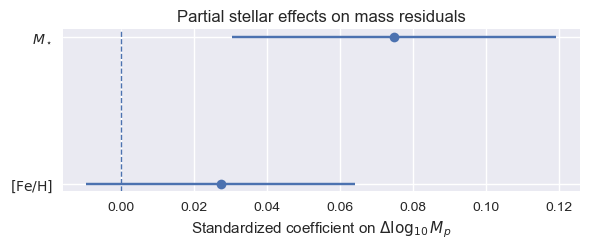

In [24]:
# ============================================================
# P5 — Figura final: partial effects sobre ΔlogMp
# ============================================================

import matplotlib.pyplot as plt

tabla_coef_plot = tabla_coef_M2_stellar[
    tabla_coef_M2_stellar["predictor"].isin(["st_mass_z", "st_met_z"])
].copy()

labels = {
    "st_mass_z": r"$M_\star$",
    "st_met_z": r"$[\mathrm{Fe/H}]$"
}

tabla_coef_plot["label"] = tabla_coef_plot["predictor"].map(labels)

# Orden: Mstar arriba, FeH abajo
tabla_coef_plot["orden"] = tabla_coef_plot["predictor"].map({
    "st_mass_z": 1,
    "st_met_z": 0
})

tabla_coef_plot = tabla_coef_plot.sort_values("orden")

tabla_coef_plot["err_low"] = (
    tabla_coef_plot["coef_standardized"] - tabla_coef_plot["IC95_low"]
)

tabla_coef_plot["err_high"] = (
    tabla_coef_plot["IC95_high"] - tabla_coef_plot["coef_standardized"]
)

plt.figure(figsize=(6, 2.6))

plt.errorbar(
    tabla_coef_plot["coef_standardized"],
    tabla_coef_plot["label"],
    xerr=[
        tabla_coef_plot["err_low"],
        tabla_coef_plot["err_high"]
    ],
    fmt="o",
    capsize=5
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.xlabel(r"Standardized coefficient on $\Delta \log_{10} M_p$")
plt.ylabel("")
plt.title("Partial stellar effects on mass residuals")

plt.tight_layout()

plt.savefig(
    "../figures/P5_outcomeII_partial_effects_mass_residuals_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

After accounting for the flexible mass–radius relation and incident flux, stellar mass remains positively associated with planetary mass residuals. A one-standard-deviation increase in stellar mass corresponds to an increase of 0.075 dex in ΔlogMp, with IC95% [0.030, 0.119]. The metallicity coefficient is positive but its confidence interval crosses zero, so it is not robust in this model.

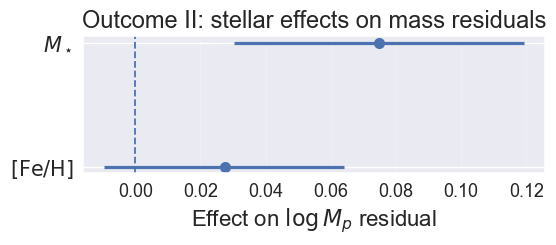

In [26]:
# ============================================================
# Outcome II poster figure — stellar effects only
# Controls: flexible mass-radius relation + incident flux
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

coef_outcomeII_stellar = pd.DataFrame({
    "predictor": [
        r"$M_\star$",
        r"$[\mathrm{Fe/H}]$"
    ],
    "coef": [
        0.0748,
        0.0274
    ],
    "ci_low": [
        0.0303,
        -0.0095
    ],
    "ci_high": [
        0.1193,
        0.0642
    ]
})

coef_outcomeII_stellar["xerr_low"] = (
    coef_outcomeII_stellar["coef"] - coef_outcomeII_stellar["ci_low"]
)

coef_outcomeII_stellar["xerr_high"] = (
    coef_outcomeII_stellar["ci_high"] - coef_outcomeII_stellar["coef"]
)

# Reverse order for plotting
coef_plot = coef_outcomeII_stellar.iloc[::-1].copy()

plt.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 17,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 15,
})

fig, ax = plt.subplots(figsize=(5.8, 2.7))

ax.errorbar(
    coef_plot["coef"],
    coef_plot["predictor"],
    xerr=[
        coef_plot["xerr_low"],
        coef_plot["xerr_high"]
    ],
    fmt="o",
    markersize=8,
    linewidth=2.3,
    capsize=5
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.3
)

ax.set_xlabel(r"Effect on $\log M_p$ residual")
ax.set_title("Outcome II: stellar effects on mass residuals")

ax.grid(axis="x", alpha=0.20)

for spine in ax.spines.values():
    spine.set_linewidth(1.1)

plt.tight_layout()

plt.savefig(
    figures / "OutcomeII_stellar_effects_mass_residuals_poster.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "OutcomeII_stellar_effects_mass_residuals_poster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

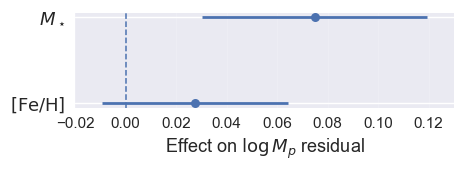

In [27]:
# ============================================================
# Outcome II compact poster figure
# Stellar effects on mass residuals
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

figures = Path("../figures")
figures.mkdir(exist_ok=True)

coef_outcomeII = pd.DataFrame({
    "predictor": [
        r"$M_\star$",
        r"$[\mathrm{Fe/H}]$"
    ],
    "coef": [
        0.0748,
        0.0274
    ],
    "ci_low": [
        0.0303,
        -0.0095
    ],
    "ci_high": [
        0.1193,
        0.0642
    ]
})

coef_outcomeII["xerr_low"] = coef_outcomeII["coef"] - coef_outcomeII["ci_low"]
coef_outcomeII["xerr_high"] = coef_outcomeII["ci_high"] - coef_outcomeII["coef"]

coef_plot = coef_outcomeII.iloc[::-1].copy()

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 13,
})

fig, ax = plt.subplots(figsize=(4.8, 1.85))

ax.errorbar(
    coef_plot["coef"],
    coef_plot["predictor"],
    xerr=[
        coef_plot["xerr_low"],
        coef_plot["xerr_high"]
    ],
    fmt="o",
    markersize=6.5,
    linewidth=2.0,
    capsize=4
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.1
)

ax.set_xlabel(r"Effect on $\log M_p$ residual")
ax.set_xlim(-0.02, 0.13)

ax.grid(axis="x", alpha=0.18)

# Remove unnecessary visual weight
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    figures / "OutcomeII_stellar_effects_mass_residuals_compact.pdf",
    bbox_inches="tight"
)

plt.savefig(
    figures / "OutcomeII_stellar_effects_mass_residuals_compact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()